# Pauli & HSI playground (first stack)

A learning notebook. It recomputes the **Pauli RGB** and the **polarimetric HSI** of the first
extracted stack step by step, starting from the calibrated scattering matrix S, and every
parameter and normalization can be changed to see what it does to the picture.

It uses the same inputs and the same maths as the pipeline (`flooded_forest/processing/polsar.py`
and `flooded_forest/plotting/polsar.py`). Sections 4 and 8 check that the notebook reproduces
the pipeline output exactly, so any change made here is a deliberate departure from it.

**Kernel:** the `polsarpro` conda env (polsarpro, rasterio, xarray, scipy). It needs a previous
`run_pipeline.py` extraction in `outputs/`. One scene takes about 1 s to read and 1 s to average,
so every cell reruns quickly.

| § | What | Main knobs |
|---|---|---|
| 1 | Load one scene of the first stack | `ROI_SLUG`, `STACK_INDEX`, `SCENE_INDEX`, `ZOOM` |
| 2 | Radiometric scaling β⁰ → σ⁰ | `SCALING` = `"none"`, `"swath"` (pipeline), `"pixel"` |
| 3 | S → T3 (Pauli basis) | none |
| 4 | Spatial averaging ⟨·⟩, plus a check against the pipeline | `WINDOW_M` |
| 5 | Pauli RGB normalizations | keywords of `pauli_rgb_image(...)` |
| 6 | H / A / α eigen-decomposition | none |
| 7 | HSI encodings | keywords of `hsi_image(...)` |
| 8 | Whole stack: per-scene vs stack-wide normalization | `PAULI`, `HSI` recipes |

All maps are in radar geometry (rows = azimuth, columns = range), and each pixel is drawn with
its true ground shape.

In [1]:
import json
import sys
from math import ceil
from pathlib import Path

import matplotlib.pyplot as plt
import netCDF4
import numpy as np
import rasterio
import xarray as xr
from matplotlib.colors import hsv_to_rgb
from polsarpro.decompositions import h_a_alpha
from polsarpro.util import S_to_T3, pauli_rgb, plot_h_alpha_plane
from scipy.interpolate import interp1d

# topic folder = first parent with config.yaml and the flooded_forest package
TOPIC_DIR = next((d for d in (Path.cwd(), *Path.cwd().parents)
                  if (d / "config.yaml").is_file() and (d / "flooded_forest").is_dir()), None)
if TOPIC_DIR is None:
    raise FileNotFoundError("open the notebook from inside topics/11-B-FLOODED-FOREST")
sys.path.insert(0, str(TOPIC_DIR))

from flooded_forest.core import config
from flooded_forest.core.io import load_stack_info
from flooded_forest.plotting.common import cell_geometry, hsi_to_rgb
from flooded_forest.processing.averaging import AveragingGrid, describe_window, print_window_table
from flooded_forest.processing.polsar import MIN_VALID_FRACTION, T3_ELEMENTS, incidence_scale, polsar_paths

plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 9, "axes.labelsize": 8,
                     "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 8})
SCALAR_CMAP = "viridis"   # scalar maps (the pipeline uses "jet")
PAULI_COLORS = {"R  T22 double bounce": "#e0302a", "G  T33 volume": "#2fa84f", "B  T11 surface": "#2a64d6"}
cfg = config.load_config()
print("topic folder:", TOPIC_DIR)

topic folder: /home/marco/Desktop/Uni/git hub/biomass-hackathon-2026/topics/11-B-FLOODED-FOREST


## 1. The data: first stack, one scene

The **stack** is the first one of the last extraction (order of `extraction_summary.json`),
restricted to the scenes kept in the manual coherence review (`scene_selection.json`).

Each product tif holds the calibrated, coregistered, phase-corrected scattering matrix as
4 complex bands (HH, HV, VH, VV). Rows are azimuth, columns are slant range, cropped to the
stack window. `overlap_mask.tif` marks the pixels inside the common area of all stacks: every
statistic below (quantiles, percentiles, means) is taken over those pixels only.

`ZOOM` is a crop box (azimuth rows, range columns) used for close-ups. Put it on an area you care about.

In [2]:
ROI_SLUG = None        # None = first ROI folder in outputs/, or e.g. "Lac_T_l_Community_Reserve_LTCR"
STACK_INDEX = 0        # 0 = first stack of the last extraction
SCENE_INDEX = 0        # kept scene used in sections 1-7 (0 = earliest)
ZOOM = (7000, 9400, 300, 1000)   # (az0, az1, rg0, rg1) crop pixels for close-ups

roi_dirs = sorted(d.name for d in cfg.outputs_dir.iterdir() if (d / "extraction").is_dir())
paths = cfg.roi_paths(ROI_SLUG or roi_dirs[0])
STACK_DIR = paths.stack_dirs()[STACK_INDEX]
info = load_stack_info(STACK_DIR, kept_only=True)
products = info["products"]
sp = info["spacings"]
THETA_SWATH = cfg.incidence_deg(info["swath"])

with rasterio.open(STACK_DIR / "overlap_mask.tif") as src:
    INSIDE = src.read(1).astype(bool)

print(f"ROI folders in outputs/: {roi_dirs}  ->  {paths.root.name}")
print(f"stack {STACK_DIR.name}: swath {info['swath']}, {info['orbit_state']}, "
      f"crop {INSIDE.shape[0]} az x {INSIDE.shape[1]} rg px, {INSIDE.mean():.0%} inside the common area")
print(f"pixel spacing: azimuth {sp['azimuth_m']:.2f} m, slant range {sp['slant_range_m']:.2f} m, "
      f"ground range {sp['ground_range_m']:.2f} m (mean incidence {sp['incidence_mean_deg']:.1f} deg)")
print("kept scenes:")
for k, p in enumerate(products):
    print(f"  [{k}] {p['datetime'][:10]}{'  primary' if p['coregistration_primary'] else ''}")

ROI folders in outputs/: ['Lac_T_l_Community_Reserve_LTCR']  ->  Lac_T_l_Community_Reserve_LTCR
stack STA3_ascending_20260606-20260624_WRS-33-2: swath S3, ascending, crop 16141 az x 1331 rg px, 68% inside the common area
pixel spacing: azimuth 6.79 m, slant range 19.81 m, ground range 37.61 m (mean incidence 31.8 deg)
kept scenes:
  [0] 2026-06-09
  [1] 2026-06-12
  [2] 2026-06-15  primary
  [3] 2026-06-18
  [4] 2026-06-21


In [3]:
def read_scattering(k):
    """Raw complex S of kept scene k: {pol: (Naz, Nrg) complex64} with NaN set to 0, and the finite mask."""
    with rasterio.open(STACK_DIR / products[k]["file"]) as src:
        bands = {pol.lower(): src.read(b) for b, pol in enumerate(src.descriptions, start=1)}
    finite = np.logical_and.reduce([np.isfinite(v) for v in bands.values()])
    for v in bands.values():
        v[~finite] = 0  # as the pipeline (BPS): no-data -> 0 before averaging
    return bands, finite


S_RAW, FINITE = read_scattering(SCENE_INDEX)
VALID_PX = INSIDE & FINITE
DATE = products[SCENE_INDEX]["datetime"][:10]
print(DATE, {pol: v.shape for pol, v in S_RAW.items()}, f"finite {FINITE.mean():.1%}")

2026-06-09 {'hh': (16141, 1331), 'hv': (16141, 1331), 'vh': (16141, 1331), 'vv': (16141, 1331)} finite 100.0%


Some plotting helpers: `show` draws a map in radar geometry with the true ground aspect, `rgba`
makes invalid cells transparent, and `compare` puts several images side by side.

In [4]:
def db(x):
    return 10 * np.log10(np.maximum(x, 1e-12))


def full_res_geometry():
    """Plot geometry of the full-resolution crop grid (same form as plotting.common.cell_geometry)."""
    win = {"subs_F_a": 1, "subs_F_r": 1,
           "output_spacing_az_m": sp["azimuth_m"], "output_spacing_rg_m": sp["ground_range_m"]}
    return cell_geometry(win, np.arange(INSIDE.shape[0]), np.arange(INSIDE.shape[1]))


GEO_FULL = full_res_geometry()


def rgba(rgb, good):
    """(..., 3) RGB in 0-1 -> RGBA, transparent outside `good` or where not finite."""
    ok = good & np.isfinite(rgb).all(axis=-1)
    return np.concatenate([np.nan_to_num(rgb), ok[..., None]], axis=-1).astype(np.float32)


def view_ratio(view):
    """Ground height / width of the whole crop (view None) or of a zoom box."""
    az0, az1, rg0, rg1 = view or (0, INSIDE.shape[0], 0, INSIDE.shape[1])
    return (az1 - az0) * sp["azimuth_m"] / ((rg1 - rg0) * sp["ground_range_m"])


def show(ax, img, geo, title="", view=None, good=None, **kw):
    """Map in radar geometry; view = zoom box (az0, az1, rg0, rg1); 2-D images are NaN outside `good`."""
    if img.ndim == 2 and good is not None:
        img = np.where(good, img, np.nan)
    kw.setdefault("interpolation", "antialiased" if geo is GEO_FULL else "nearest")
    im = ax.imshow(img, extent=geo["extent"], aspect=geo["px_aspect"], **kw)
    if view:
        ax.set_xlim(view[2], view[3])
        ax.set_ylim(view[1], view[0])
    ax.set_title(title, fontsize=8)
    ax.tick_params(labelsize=6)
    return im


def panel_grid(n, view=None, ncols=4, panel_w=3.3, extra_rows=None):
    """Figure with n map panels (true ground aspect); extra_rows = height ratio of a key row under each map row."""
    ncols = min(ncols, n)
    nrows = ceil(n / ncols)
    panel_h = float(np.clip(panel_w * view_ratio(view), 1.5, 8.0))
    if extra_rows is None:
        fig, axes = plt.subplots(nrows, ncols, figsize=(panel_w * ncols, panel_h * nrows + 0.6),
                                 squeeze=False, layout="constrained")
        return fig, list(axes.ravel()), []
    fig, axes = plt.subplots(2 * nrows, ncols, figsize=(panel_w * ncols, (panel_h + extra_rows) * nrows + 0.6),
                             squeeze=False, layout="constrained", height_ratios=[panel_h, extra_rows] * nrows)
    maps = [ax for r in range(0, 2 * nrows, 2) for ax in axes[r]]
    keys = [ax for r in range(1, 2 * nrows, 2) for ax in axes[r]]
    for ax in maps[n:] + keys[n:]:
        ax.axis("off")
    return fig, maps, keys

### 1a. The four channels (single look)

These are the intensities |HH|², |HV|², |VH|², |VV|² in dB on a shared colour scale. The cross-pol
channels are several dB darker. Full-resolution data is speckled, but the display downsampling
smooths the whole-crop view; the close-up in section 3 shows the real speckle.

The Pauli vector adds HV and VH together, which assumes **reciprocity** (HV = VH). The cell
below checks it: the power ratio should be about 0 dB and the HV/VH coherence close to 1.

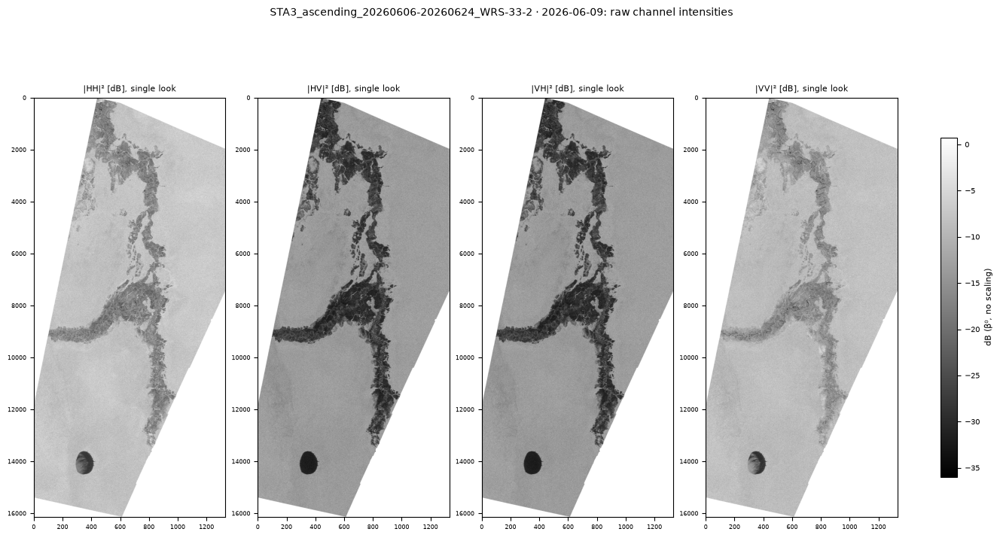

reciprocity: <|HV|^2>/<|VH|^2> = -0.003 dB, |<HV VH*>| / sqrt(<|HV|^2><|VH|^2>) = 0.982


In [5]:
powers = {pol: db(np.abs(v) ** 2) for pol, v in S_RAW.items()}
lo, hi = np.percentile(powers["hv"][VALID_PX][::7], 2), np.percentile(powers["hh"][VALID_PX][::7], 98)
fig, axes = panel_grid(4)[:2]
for ax, (pol, p) in zip(axes, powers.items()):
    im = show(ax, p, GEO_FULL, f"|{pol.upper()}|² [dB], single look", good=VALID_PX, cmap="gray", vmin=lo, vmax=hi)
fig.colorbar(im, ax=axes, shrink=0.6, label="dB (β⁰, no scaling)")
fig.suptitle(f"{STACK_DIR.name} · {DATE}: raw channel intensities", fontsize=10)
plt.show()

hv, vh = S_RAW["hv"][VALID_PX], S_RAW["vh"][VALID_PX]
p_hv, p_vh = np.mean(np.abs(hv) ** 2), np.mean(np.abs(vh) ** 2)
print(f"reciprocity: <|HV|^2>/<|VH|^2> = {db(p_hv / p_vh):+.3f} dB, "
      f"|<HV VH*>| / sqrt(<|HV|^2><|VH|^2>) = {np.abs(np.mean(hv * vh.conj())) / np.sqrt(p_hv * p_vh):.3f}")
del powers, hv, vh

## 2. Radiometric scaling: β⁰ → σ⁰

The pipeline treats the L1C amplitude as √β⁰ and multiplies S by √sin θ, so that |S|² becomes
σ⁰ = β⁰ sin θ. It uses **one θ per swath** (`swath_incidence_deg` in `config.yaml`). The geometry
LUT also gives θ for every pixel, so this notebook offers three options:

* `"none"`: keep β⁰
* `"swath"`: one constant θ per swath (what the pipeline does)
* `"pixel"`: θ of every pixel, interpolated from `geometry_lut.nc`

**Key fact.** A constant factor c on S multiplies every T3 element by c², which shifts every
dB value by the same 20·log10 c. Any normalization that divides by a statistic of the image
itself (quantile clip, percentile stretch) cancels that factor exactly, so `"none"` and `"swath"`
give *identical* Pauli and HSI images (checked in section 5d). The scaling only matters for
**fixed physical limits** (e.g. "−25 to −5 dB") and for comparisons between stacks/swaths.
A per-pixel θ does not cancel, because it is a ramp across range.

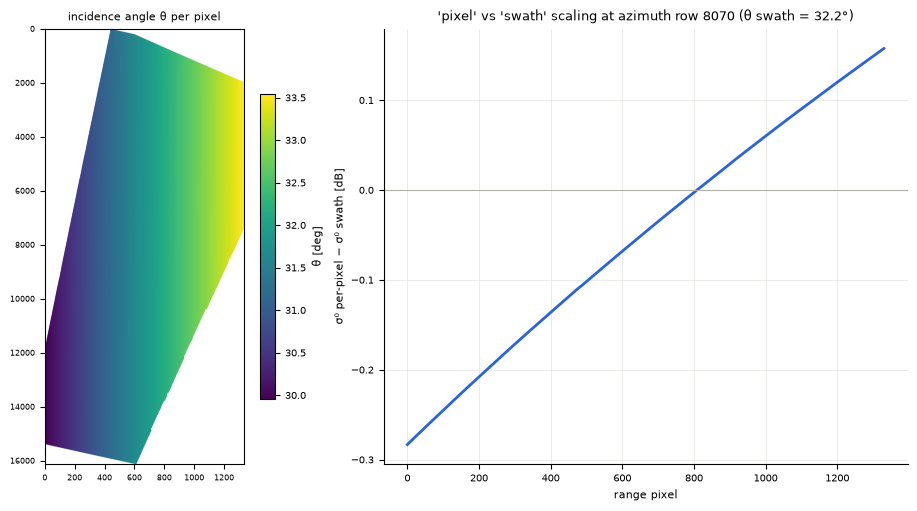

theta in the crop: 29.96 to 33.54 deg; constant swath scaling = -2.73 dB on every T3 element


In [6]:
SCALING = "swath"   # "none" (beta0), "swath" (pipeline), "pixel" (theta of every pixel)


def incidence_map():
    """theta [deg] of every crop pixel: separable linear interpolation of the geometry LUT nodes."""
    with netCDF4.Dataset(STACK_DIR / "geometry_lut.nc") as nc:
        lut = nc["incidenceAngle"][:].filled(np.nan)
        nodes_a = int(nc.lut_row_offset) + int(nc.azimuth_step) * np.arange(lut.shape[0])
        nodes_r = int(nc.lut_col_offset) + int(nc.range_step) * np.arange(lut.shape[1])
    rows = interp1d(nodes_r, lut, axis=1, fill_value="extrapolate")(np.arange(INSIDE.shape[1]))
    return interp1d(nodes_a, rows, axis=0, fill_value="extrapolate")(np.arange(INSIDE.shape[0])).astype(np.float32)


def scale_factor(scaling):
    """Factor applied to S: 1, sqrt(sin(theta_swath)) or sqrt(sin(theta_pixel))."""
    if scaling == "none":
        return np.float32(1)
    if scaling == "swath":
        return incidence_scale(THETA_SWATH)
    if scaling == "pixel":
        return np.sqrt(np.sin(np.deg2rad(THETA_PX))).astype(np.float32)
    raise ValueError(f"SCALING must be 'none', 'swath' or 'pixel', not {scaling!r}")


THETA_PX = incidence_map()
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 5), width_ratios=[1, 1.6], layout="constrained")
im = show(ax0, THETA_PX, GEO_FULL, "incidence angle θ per pixel", good=VALID_PX, cmap=SCALAR_CMAP)
fig.colorbar(im, ax=ax0, shrink=0.7, label="θ [deg]")
row = INSIDE.shape[0] // 2
ax1.plot(np.arange(INSIDE.shape[1]), db(np.sin(np.deg2rad(THETA_PX[row])) / np.sin(np.deg2rad(THETA_SWATH))),
         color="#2a64d6", lw=2)
ax1.axhline(0, color="#b0b0a8", lw=0.8)
ax1.set_xlabel("range pixel")
ax1.set_ylabel("σ⁰ per-pixel − σ⁰ swath [dB]")
ax1.set_title(f"'pixel' vs 'swath' scaling at azimuth row {row} (θ swath = {THETA_SWATH}°)", fontsize=9)
ax1.grid(color="#e4e3dd", lw=0.5)
ax1.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"theta in the crop: {THETA_PX[VALID_PX].min():.2f} to {THETA_PX[VALID_PX].max():.2f} deg; "
      f"constant swath scaling = {db(incidence_scale(THETA_SWATH) ** 2):+.2f} dB on every T3 element")

## 3. From S to the coherency matrix T3

The Pauli scattering vector splits S into three elementary mechanisms:

$$\mathbf{k} = \tfrac{1}{\sqrt 2}\,[\,S_{HH}+S_{VV},\; S_{HH}-S_{VV},\; S_{HV}+S_{VH}\,]^T,\qquad T_3 = \langle \mathbf{k}\,\mathbf{k}^H \rangle$$

Its diagonal is the power of each mechanism, and those three powers are the Pauli RGB:

| element | formula | mechanism | Pauli colour |
|---|---|---|---|
| T11 | ⟨\|HH+VV\|²⟩/2 | odd bounce: surface | **B** |
| T22 | ⟨\|HH−VV\|²⟩/2 | even bounce: double bounce (water surface + trunks in flooded forest) | **R** |
| T33 | ⟨\|HV+VH\|²⟩/2 = 2⟨\|HV\|²⟩ | cross-pol: volume (canopy) | **G** |

span = T11 + T22 + T33 is the total power. ⟨·⟩ is the spatial average (section 4). Without
it, T3 is the single-look k kᴴ. `polsarpro.util.S_to_T3` does exactly this; the cell checks
it by hand on a small block.

In [7]:
def to_t3(scaling=SCALING, k=None):
    """Single-look T3 (polsarpro S_to_T3) of kept scene k (default: the loaded one) and its finite mask."""
    bands, finite = (S_RAW, FINITE) if k is None else read_scattering(k)
    c = scale_factor(scaling)
    s = xr.Dataset({pol: (("y", "x"), (v * c).astype(np.complex64)) for pol, v in bands.items()},
                   attrs={"poltype": "S", "description": "Scattering matrix"})
    return S_to_T3(s), finite


T3_SL, _ = to_t3(SCALING)

# check S_to_T3 by hand on a block
blk = np.s_[8000:8200, 400:600]
c = scale_factor(SCALING)
c = c[blk] if np.ndim(c) else c
hh, hv, vh, vv = (S_RAW[p][blk] * c for p in ("hh", "hv", "vh", "vv"))
kvec = np.stack([hh + vv, hh - vv, hv + vh]) / np.sqrt(2)
t_hand = np.einsum("i...,j...->ij...", kvec, kvec.conj())
for (i, j), name in zip([(0, 0), (1, 1), (2, 2), (0, 1), (0, 2), (1, 2)], T3_ELEMENTS):
    ref = T3_SL[name].values[blk]
    print(f"T{i + 1}{j + 1} ({name}): max |by hand - S_to_T3| / max|T| = "
          f"{np.max(np.abs(t_hand[i, j] - ref)) / np.max(np.abs(ref)):.1e}")
del hh, hv, vh, vv, kvec, t_hand

T11 (m11): max |by hand - S_to_T3| / max|T| = 8.9e-08
T22 (m22): max |by hand - S_to_T3| / max|T| = 8.6e-08
T33 (m33): max |by hand - S_to_T3| / max|T| = 6.8e-08
T12 (m12): max |by hand - S_to_T3| / max|T| = 9.8e-08
T13 (m13): max |by hand - S_to_T3| / max|T| = 9.4e-08
T23 (m23): max |by hand - S_to_T3| / max|T| = 1.1e-07


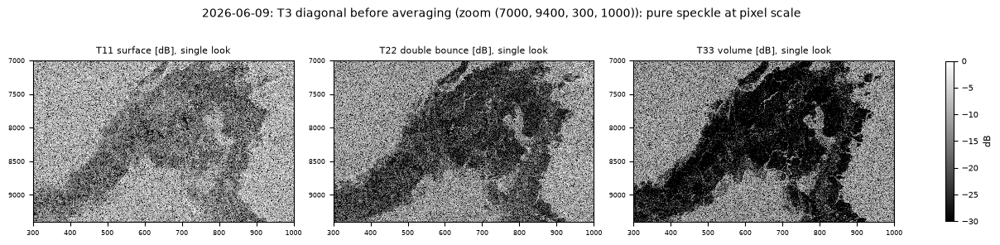

In [8]:
fig, axes = panel_grid(3, view=ZOOM, ncols=3, panel_w=4)[:2]
for ax, name, label in zip(axes, ("m11", "m22", "m33"), ("T11 surface", "T22 double bounce", "T33 volume")):
    im = show(ax, db(T3_SL[name].values), GEO_FULL, f"{label} [dB], single look", view=ZOOM,
              good=VALID_PX, cmap="gray", vmin=-30, vmax=0, interpolation="nearest")
fig.colorbar(im, ax=axes, shrink=0.7, label="dB")
fig.suptitle(f"{DATE}: T3 diagonal before averaging (zoom {ZOOM}): pure speckle at pixel scale", fontsize=10)
plt.show()

## 4. Spatial averaging ⟨·⟩

Averaging is essential. A single-look T3 = k kᴴ has rank 1, so its eigenvalues are (λ, 0, 0)
and the entropy is **exactly 0** everywhere (checked in section 6). The window size sets:

* **speckle**: more looks give a smoother image;
* **resolution**: larger windows mean coarser cells;
* **bias of H/A/α**: with few looks the entropy is underestimated (section 6).

The pipeline uses the BPS rule for coherence and PolSAR: a window side L in metres on ground
gives an odd boxcar of `NW = int(L / spacing / 2) * 2 + 1` pixels per axis, decimated by
`(NW − 1) / 2`. Each cell is normalized by the share of pixels with data, and cells with less
than 50 % of their window inside the common area are NaN. Azimuth pixels are about 6.8 m and
ground-range pixels about 38 m, so the window is much longer in pixels along azimuth.

`average_t3(t3, finite, window_m)` below does the same thing (window_m = 0 → no averaging).

In [9]:
print_window_table([(f"{w:g} m", describe_window(w, sp)) for w in (50, 100, 250, 500, 1000)])


def average_t3(t3_full, finite, window_m):
    """Pipeline averaging (processing.polsar.averaged_t3): BPS boxcar of window_m on ground + decimation.

    Returns the averaged T3 dataset (NaN on invalid cells), the valid-cell mask and the plot geometry.
    window_m = 0: no averaging (single look, full grid).
    """
    if not window_m:
        return t3_full, INSIDE & finite, GEO_FULL
    win = describe_window(window_m, sp)
    grid = AveragingGrid(INSIDE.shape, win)
    share = grid.average(finite.astype(np.float64))
    good = grid.average((INSIDE & finite).astype(np.float64)) >= MIN_VALID_FRACTION
    norm = np.where(good, 1 / np.maximum(share, 1e-12), np.nan)
    data = {}
    for name in T3_ELEMENTS:
        x = t3_full[name].values
        cplx = np.iscomplexobj(x)
        avg = grid.average(x.astype(np.complex128 if cplx else np.float64)) * norm
        data[name] = (("y", "x"), avg.astype(np.complex64 if cplx else np.float32))
    t3 = xr.Dataset(data, coords={"y": np.arange(grid.shape_out[0]), "x": np.arange(grid.shape_out[1])},
                    attrs={"poltype": "T3", "description": "Coherency matrix (3x3), averaged"})
    return t3, good, cell_geometry(win, grid.az_index, grid.rg_index)


WINDOW_M = 250   # window used from here on (pipeline: averaging_window in config.yaml)
T3_AVG, GOOD, GEO = average_t3(T3_SL, FINITE, WINDOW_M)
print(f"{WINDOW_M} m window -> grid {GOOD.shape[0]} x {GOOD.shape[1]} cells, {GOOD.sum()} valid")

# check against the stored pipeline result (same scene, 250 m, 'swath' scaling)
npz_path = polsar_paths(paths.polsar / STACK_DIR.name, WINDOW_M)[0]
if npz_path.exists() and SCALING == "swath":
    meta = json.loads(npz_path.with_suffix(".json").read_text(encoding="utf-8"))
    with np.load(npz_path) as z:
        ref = z["t3"][meta["products"].index(products[SCENE_INDEX]["id"])]
    for n, name in enumerate(T3_ELEMENTS):
        a, b = T3_AVG[name].values[GOOD], ref[n][GOOD]
        print(f"  {name}: max |notebook - pipeline| / max|pipeline| = {np.max(np.abs(a - b)) / np.max(np.abs(b)):.1e}")
else:
    print(f"no pipeline result to compare with ({npz_path.name}, scaling {SCALING!r})")


  stack                                          window (az x rg)       on ground (az x rg)   rg/az  looks  output grid
  50 m                                             7 x  1 px        48 x    38 m    0.79      7  20 x 38 m
  100 m                                           15 x  3 px       102 x   113 m    1.11     45  48 x 38 m
  250 m                                           37 x  7 px       251 x   263 m    1.05    259  122 x 113 m
  500 m                                           73 x 13 px       496 x   489 m    0.99    949  245 x 226 m
  1000 m                                         147 x 27 px       998 x  1015 m    1.02   3969  496 x 489 m

250 m window -> grid 897 x 444 cells, 271756 valid
  m11: max |notebook - pipeline| / max|pipeline| = 0.0e+00
  m22: max |notebook - pipeline| / max|pipeline| = 0.0e+00
  m33: max |notebook - pipeline| / max|pipeline| = 0.0e+00
  m12: max |notebook - pipeline| / max|pipeline| = 0.0e+00
  m13: max |notebook - pipeline| / max|pipeline| =

### 4a. Effect of the window: polsarpro `pauli_rgb` at several windows (close-up)

This uses polsarpro's own `pauli_rgb` (√Tii, each channel clipped at its own 98 % quantile),
which is what the pipeline stores in the npz. Section 5 opens up that normalization.

In the single-look panel the 98 % quantile comes from the speckle tail, far above the typical
value, so the whole image goes dark and grey. The window size changes the colours as well as
the sharpness.

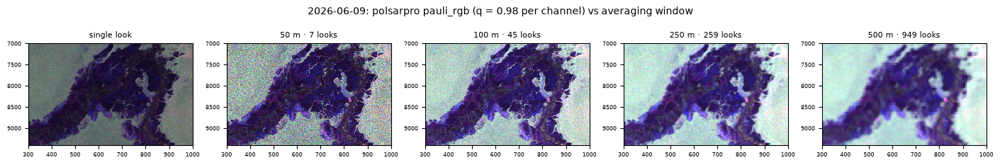

In [10]:
WINDOWS_TO_COMPARE = (0, 50, 100, 250, 500)

fig, axes = panel_grid(len(WINDOWS_TO_COMPARE), view=ZOOM, ncols=5, panel_w=2.8)[:2]
for ax, w in zip(axes, WINDOWS_TO_COMPARE):
    t3, good, geo = average_t3(T3_SL, FINITE, w)
    rgb = pauli_rgb(t3).compute().transpose(..., "band").values
    looks = describe_window(w, sp)["looks"] if w else 1
    show(ax, rgba(rgb, good), geo, f"{w:g} m · {looks} looks" if w else "single look", view=ZOOM)
fig.suptitle(f"{DATE}: polsarpro pauli_rgb (q = 0.98 per channel) vs averaging window", fontsize=10)
plt.show()

## 5. Pauli RGB: what the normalization does

Pauli RGB = (R, G, B) = (T22, T33, T11), with each channel squashed into 0–1. The physics is
fixed; **the normalization is a choice**, and it decides what the colours mean.

`pauli_rgb_image(t3, good, **kwargs)` exposes the choices:

| keyword | options | pipeline |
|---|---|---|
| `scale` | `"amplitude"` √T, `"power"` T, `"db"` 10·log10 T | `"amplitude"` |
| `clip` | `"per_channel"`: each channel / its own q-quantile<br>`"common"`: all channels / one value (the largest per-channel q-quantile), so the **channel ratios are kept**<br>`"stretch"`: each channel from its low to its high percentile<br>`"fixed"`: fixed `limits` (same units as `scale`) for all channels | `"per_channel"` |
| `q`, `percentiles`, `limits` | numbers for the clips above | `q=0.98` |
| `gamma` | final out^(1/γ); note amplitude = power with γ = 2 | 1 |
| `weights` | factors on the (R, G, B) powers | (1, 1, 1) |
| `stats` | list of `(t3, good)` scenes to take the statistics from (default: this scene) → **stack-wide** clip | stack-wide in the figures |

Note: polsarpro's `pauli_rgb` gives a different channel *weight* depending on its input. From S
it uses |HH−VV|², |(HV+VH)/2|², |HH+VV|² (i.e. weights 2, ½, 2 on T22, T33, T11); from T3 it
uses T22, T33, T11. With `"per_channel"` this makes no difference, because a constant per
channel cancels. With `"common"` or `"fixed"` it does, so these weights are a convention too.

In [11]:
def pauli_values(t3, scale="amplitude", weights=(1, 1, 1)):
    """(Naz, Nrg, 3) R G B = T22, T33, T11 (times weights) as power, amplitude or dB."""
    p = np.stack([t3["m22"].values, t3["m33"].values, t3["m11"].values], axis=-1).astype(np.float64)
    p = np.clip(p, 0, None) * np.asarray(weights, dtype=np.float64)
    if scale == "power":
        return p
    if scale == "amplitude":
        return np.sqrt(p)
    if scale == "db":
        return db(p)
    raise ValueError(f"scale must be 'power', 'amplitude' or 'db', not {scale!r}")


def pauli_limits(pooled, clip="per_channel", q=0.98, percentiles=(2, 98), limits=None, scale="amplitude"):
    """(lo, hi) arrays of 3 channels from pooled (N, 3) values of the valid cells."""
    if clip in ("per_channel", "common"):
        if scale == "db":
            raise ValueError("a quantile clip from 0 needs scale 'power' or 'amplitude'; with 'db' use 'stretch' or 'fixed'")
        hi = np.quantile(pooled, q, axis=0)
        return np.zeros(3), (np.full(3, hi.max()) if clip == "common" else hi)
    if clip == "stretch":
        lo, hi = np.percentile(pooled, percentiles, axis=0)
        return lo, hi
    if clip == "fixed":
        return np.full(3, float(limits[0])), np.full(3, float(limits[1]))
    raise ValueError(f"clip must be 'per_channel', 'common', 'stretch' or 'fixed', not {clip!r}")


def pauli_rgb_image(t3, good, scale="amplitude", clip="per_channel", q=0.98, percentiles=(2, 98),
                    limits=None, gamma=1.0, weights=(1, 1, 1), stats=None):
    """Pauli RGBA image (Naz, Nrg, 4) and the (lo, hi) used per channel.

    stats: list of (t3, good) whose valid cells give the clip statistics (default: this scene only).
    """
    values = pauli_values(t3, scale, weights)
    pooled = np.concatenate([pauli_values(t, scale, weights)[g] for t, g in (stats or [(t3, good)])])
    pooled = pooled[np.isfinite(pooled).all(axis=1)]
    lo, hi = pauli_limits(pooled, clip, q, percentiles, limits, scale)
    rgb = np.clip((values - lo) / (hi - lo), 0, 1) ** (1 / gamma)
    return rgba(rgb, good), (lo, hi)


def compare_pauli(variants, t3=None, good=None, geo=None, view=None, ncols=4, panel_w=3.3, title=""):
    """One panel per variant: variants = {panel title: keyword arguments of pauli_rgb_image}."""
    t3, good, geo = (T3_AVG, GOOD, GEO) if t3 is None else (t3, good, geo)
    fig, axes = panel_grid(len(variants), view=view, ncols=ncols, panel_w=panel_w)[:2]
    for ax, (name, kw) in zip(axes, variants.items()):
        img, (lo, hi) = pauli_rgb_image(t3, good, **kw)
        show(ax, img, geo, name, view=view)
        print(f"{name:<40s} lo R G B = {np.round(lo, 3)}   hi R G B = {np.round(hi, 3)}")
    for ax in axes[len(variants):]:
        ax.axis("off")
    fig.suptitle(title or f"{DATE} · {WINDOW_M:g} m window · scaling '{SCALING}'", fontsize=10)
    plt.show()

### 5a. Check: the default equals polsarpro `pauli_rgb`, and why the forest looks white

The histograms show the three Pauli powers in dB, with the per-channel 98 % clips as vertical
lines in each channel's colour and the "common" clip in black. With per-channel clipping, each
channel's bulk ends up about as close to its own clip as the others do, so R ≈ G ≈ B over most of
the forest (grey-white). The colour then only shows *relative* departures from the scene's own
distribution, not which mechanism is strongest.

max |pauli_rgb_image - polsarpro pauli_rgb| on valid cells = 1.2e-07


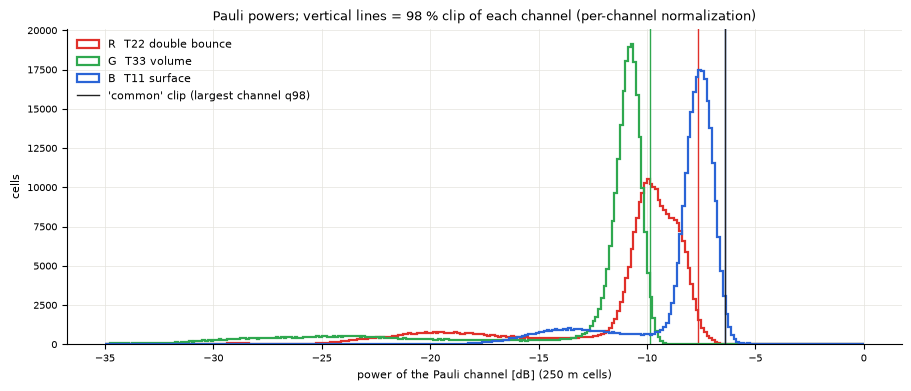

R  T22 double bounce   median   -9.9 dB   98 % clip   -7.7 dB
G  T33 volume          median  -11.0 dB   98 % clip   -9.8 dB
B  T11 surface         median   -7.7 dB   98 % clip   -6.4 dB


In [12]:
mine, (lo, hi) = pauli_rgb_image(T3_AVG, GOOD)
ref = pauli_rgb(T3_AVG).compute().transpose(..., "band").values
print(f"max |pauli_rgb_image - polsarpro pauli_rgb| on valid cells = {np.nanmax(np.abs(mine[..., :3] - ref)[GOOD]):.1e}")

powers = pauli_values(T3_AVG, "power")[GOOD]
fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
bins = np.linspace(-35, 0, 281)
for b, (name, color) in enumerate(PAULI_COLORS.items()):
    ax.hist(db(powers[:, b]), bins=bins, histtype="step", color=color, lw=1.6, label=name)
    ax.axvline(db(hi[b] ** 2), color=color, lw=1)
ax.axvline(db(hi.max() ** 2), color="#222222", lw=1, label="'common' clip (largest channel q98)")
ax.set_xlabel(f"power of the Pauli channel [dB] ({WINDOW_M:g} m cells)")
ax.set_ylabel("cells")
ax.set_title("Pauli powers; vertical lines = 98 % clip of each channel (per-channel normalization)", fontsize=9)
ax.legend(frameon=False)
ax.grid(color="#e4e3dd", lw=0.5)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
for b, name in enumerate(PAULI_COLORS):
    print(f"{name:<22s} median {np.median(db(powers[:, b])):6.1f} dB   98 % clip {db(hi[b] ** 2):6.1f} dB")

### 5b. Clip strategies (whole crop)

* **per channel 98 %** (pipeline): maximal contrast per channel, but the channels are no longer comparable.
* **common 98 %**: one divisor for all three, so a pixel is red only if double bounce really is
  stronger than the other two mechanisms *in power*.
* **stretch 2–98 %**: like per-channel, but the low end is lifted too, so dark areas (open water) gain contrast.
* **fixed dB**: physical limits, independent of the scene, so different scenes and stacks are directly comparable.

What to notice: with `common` and `fixed` the forest turns pink-lavender rather than green.
In absolute power T11 > T22 > T33 over the forest as well (histogram in 5a). So the green of
the standard Pauli means "more volume than this scene's typical cell", not "volume is the
strongest mechanism".

per channel 98 % (pipeline)              lo R G B = [0. 0. 0.]   hi R G B = [0.414 0.322 0.478]
common 98 % (keeps ratios)               lo R G B = [0. 0. 0.]   hi R G B = [0.478 0.478 0.478]
stretch 2–98 % per channel               lo R G B = [0.073 0.033 0.161]   hi R G B = [0.414 0.322 0.478]
fixed dB (-25, -5)                       lo R G B = [-25. -25. -25.]   hi R G B = [-5. -5. -5.]


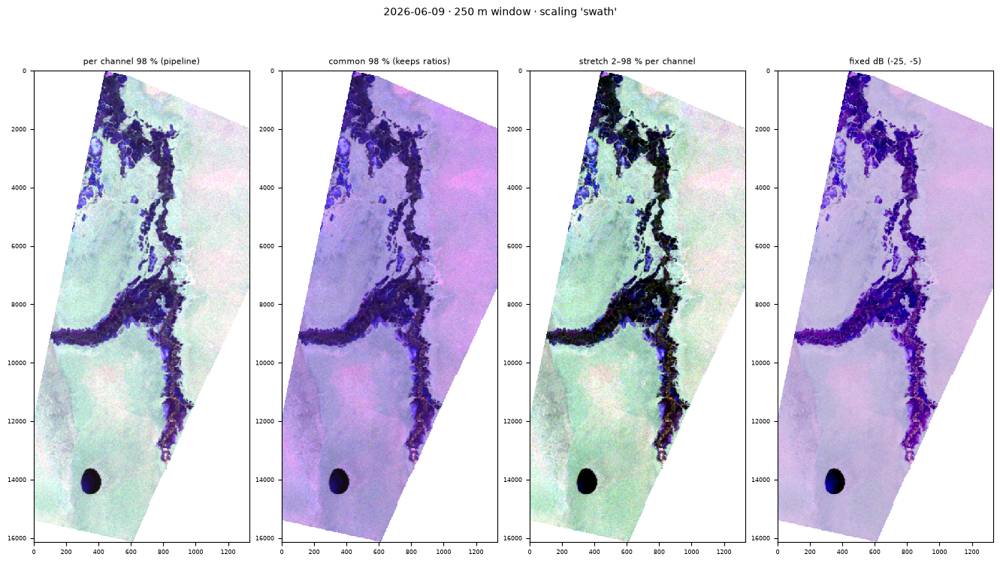

In [13]:
FIXED_DB = (-25, -5)   # fixed limits [dB] for the "fixed" clip (see the histogram above)

compare_pauli({
    "per channel 98 % (pipeline)": dict(),
    "common 98 % (keeps ratios)": dict(clip="common"),
    "stretch 2–98 % per channel": dict(clip="stretch"),
    f"fixed dB {FIXED_DB}": dict(scale="db", clip="fixed", limits=FIXED_DB),
})

### 5c. Power, amplitude or dB (close-up)

Same clip family, different transfer curve. Power is dominated by the few brightest cells
(dark image). Amplitude (= power with γ = 2) is the usual compromise. dB compresses everything,
which gives the most visible detail but the weakest colour contrast.

power, per channel 98 %                  lo R G B = [0. 0. 0.]   hi R G B = [0.172 0.104 0.229]
amplitude, per channel 98 % (pipeline)   lo R G B = [0. 0. 0.]   hi R G B = [0.414 0.322 0.478]
dB, stretch 2–98 %                       lo R G B = [-22.777 -29.596 -15.871]   hi R G B = [-7.653 -9.844 -6.404]
amplitude, common 98 %, γ 1.5            lo R G B = [0. 0. 0.]   hi R G B = [0.478 0.478 0.478]


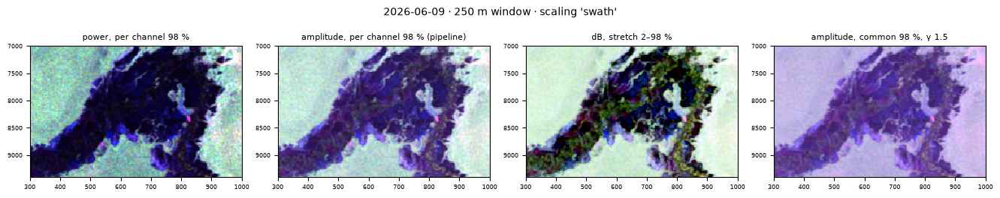

In [14]:
compare_pauli({
    "power, per channel 98 %": dict(scale="power"),
    "amplitude, per channel 98 % (pipeline)": dict(),
    "dB, stretch 2–98 %": dict(scale="db", clip="stretch"),
    "amplitude, common 98 %, γ 1.5": dict(clip="common", gamma=1.5),
}, view=ZOOM)

### 5d. Does the β⁰ → σ⁰ scaling change the picture?

The cell recomputes T3 with each scaling and compares it with the `"swath"` result, once with a
data-driven clip and once with fixed dB limits. Expected: `"none"` = `"swath"` exactly with the
quantile clip, but not with fixed limits.

In [15]:
results = {}
for s in ("none", "swath", "pixel"):
    t3_s, good_s, _ = average_t3(to_t3(s)[0], FINITE, WINDOW_M)
    results[s] = (pauli_rgb_image(t3_s, good_s)[0], pauli_rgb_image(t3_s, good_s, scale="db", clip="fixed", limits=FIXED_DB)[0])
    del t3_s
for s in ("none", "pixel"):
    d_q = np.abs(results[s][0] - results["swath"][0])[GOOD].max()
    d_f = np.abs(results[s][1] - results["swath"][1])[GOOD].max()
    print(f"'{s}' vs 'swath':  per-channel 98 % clip max diff {d_q:.3f}    fixed dB {FIXED_DB} max diff {d_f:.3f}")
del results

'none' vs 'swath':  per-channel 98 % clip max diff 0.000    fixed dB (-25, -5) max diff 0.137
'pixel' vs 'swath':  per-channel 98 % clip max diff 0.040    fixed dB (-25, -5) max diff 0.014


### 5e. Your turn

Edit the dictionary: each entry becomes one panel. Use `view=ZOOM` for close-ups and `view=None`
for the whole crop. To try another window, recompute
`t3, good, geo = average_t3(T3_SL, FINITE, 100)` and pass `t3=t3, good=good, geo=geo`.

per channel q = 0.95                     lo R G B = [0. 0. 0.]   hi R G B = [0.399 0.314 0.465]
per channel q = 0.995                    lo R G B = [0. 0. 0.]   hi R G B = [0.437 0.332 0.5  ]
common, weights (1, 2, 1)                lo R G B = [0. 0. 0.]   hi R G B = [0.478 0.478 0.478]
dB fixed (−22, −6), γ 1.3                lo R G B = [-22. -22. -22.]   hi R G B = [-6. -6. -6.]


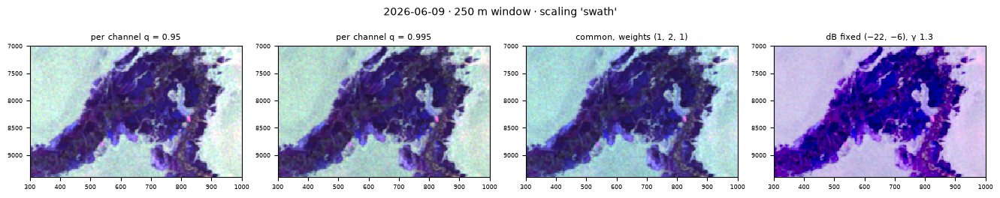

In [16]:
compare_pauli({
    "per channel q = 0.95": dict(q=0.95),
    "per channel q = 0.995": dict(q=0.995),
    "common, weights (1, 2, 1)": dict(clip="common", weights=(1, 2, 1)),
    "dB fixed (−22, −6), γ 1.3": dict(scale="db", clip="fixed", limits=(-22, -6), gamma=1.3),
}, view=ZOOM)

## 6. H / A / α: the eigen-decomposition of T3

T3 is Hermitian, so it has eigenvalues λ1 ≥ λ2 ≥ λ3 ≥ 0 with eigenvectors u_i. With
p_i = λ_i / Σλ:

* **entropy** H = −Σ p_i log₃ p_i: 0 means one pure mechanism, 1 means random scattering;
* **anisotropy** A = (p2 − p3)/(p2 + p3): relative weight of the 2nd vs the 3rd mechanism;
* **α_i** = arccos |u_i[0]|: 0° surface, 45° dipole/volume, 90° double bounce;
* **ᾱ** = Σ p_i α_i is the mean α (pipeline `alpha_averaged`, used for the HSI hue); α1 is the
  α of the dominant eigenvector (used by the pipeline's dominant-mechanism map).

`polsarpro.decompositions.h_a_alpha` is called with `boxcar_size=[1, 1]` because T3 is already
averaged. Its default `[3, 3]` would average a second time.

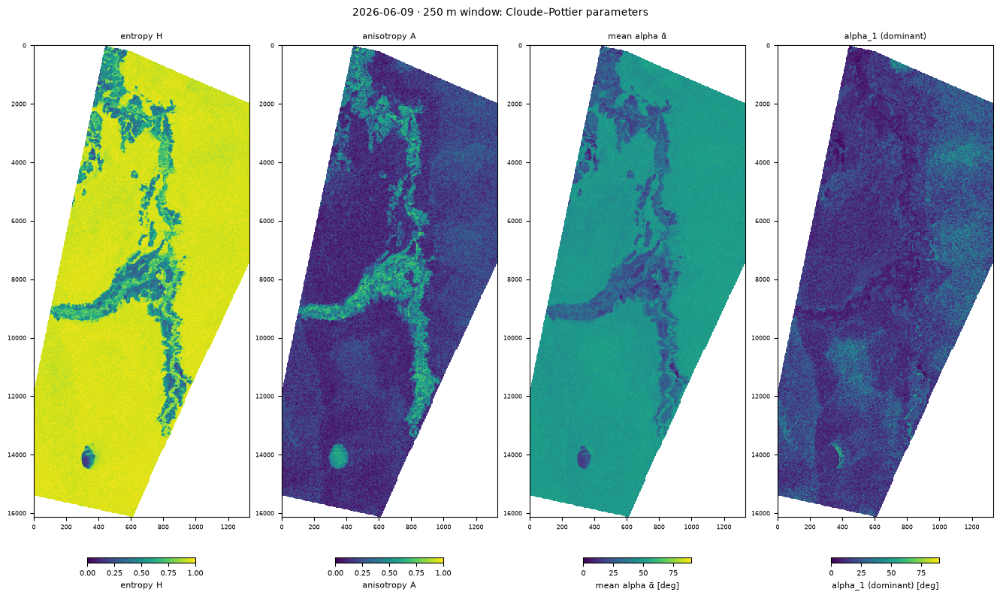

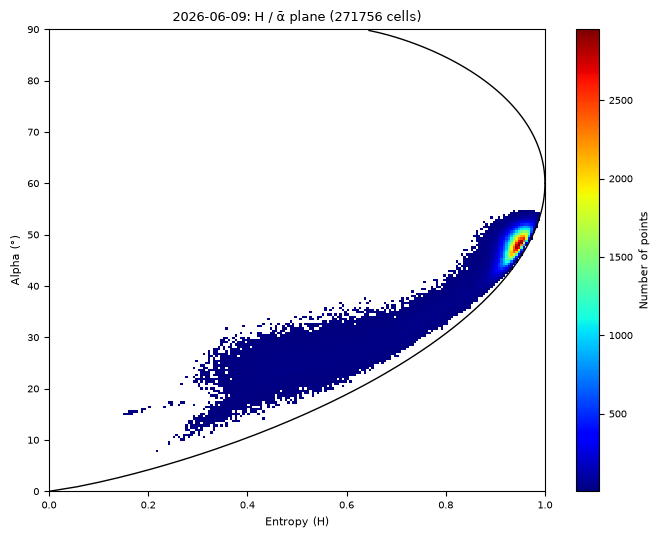

In [17]:
FLAGS = ("entropy", "anisotropy", "alpha", "alphas", "lambdas")


def eigen(t3):
    """H, A, mean alpha, alpha_1, lambdas and span of an averaged T3 dataset."""
    e = h_a_alpha(t3, boxcar_size=[1, 1], flags=FLAGS).compute()
    return {"H": e["entropy"].values, "A": e["anisotropy"].values, "alpha": e["alpha"].values,
            "alpha_1": e["alphas"].values[..., 0], "lambdas": e["lambdas"].values,
            "span": (t3["m11"] + t3["m22"] + t3["m33"]).values}


EIG = eigen(T3_AVG)

fig, axes = panel_grid(4)[:2]
for ax, (key, name, vmax, unit) in zip(axes, [("H", "entropy H", 1, ""), ("A", "anisotropy A", 1, ""),
                                              ("alpha", "mean alpha ᾱ", 90, " [deg]"),
                                              ("alpha_1", "alpha_1 (dominant)", 90, " [deg]")]):
    im = show(ax, EIG[key], GEO, name, good=GOOD, cmap=SCALAR_CMAP, vmin=0, vmax=vmax)
    fig.colorbar(im, ax=ax, shrink=0.5, location="bottom", label=name + unit)
fig.suptitle(f"{DATE} · {WINDOW_M:g} m window: Cloude–Pottier parameters", fontsize=10)
plt.show()

ds = xr.Dataset({"entropy": (("y", "x"), np.where(GOOD, EIG["H"], np.nan)),
                 "alpha": (("y", "x"), np.where(GOOD, EIG["alpha"], np.nan))}, attrs={"poltype": "h_a_alpha"})
ax, fig = plot_h_alpha_plane(ds, bins=200, min_pts=5)
ax.set_title(f"{DATE}: H / ᾱ plane ({int(GOOD.sum())} cells)", fontsize=9)
plt.show()

### 6a. Entropy depends on the window

A single look gives H = 0 exactly (rank 1). With few looks H is biased low, and it rises towards
its true value as the window grows. Because the HSI saturation is 1 − H, **the window size
directly changes how colourful the HSI is**.

single look (200 x 200 block): max H = 1.1e-06
     50 m      7 looks   H median 0.727   ᾱ median  45.8 deg
    100 m     45 looks   H median 0.898   ᾱ median  46.8 deg
    150 m     69 looks   H median 0.913   ᾱ median  47.0 deg
    250 m    259 looks   H median 0.934   ᾱ median  47.5 deg
    500 m    949 looks   H median 0.941   ᾱ median  47.9 deg
   1000 m   3969 looks   H median 0.943   ᾱ median  48.1 deg


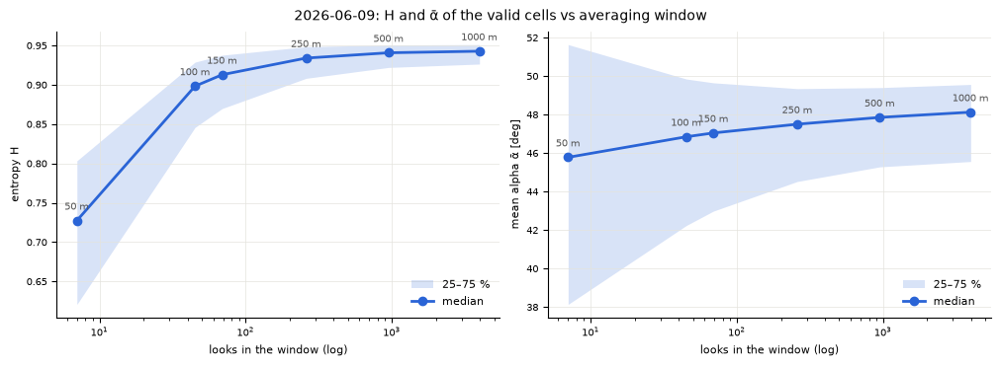

In [18]:
eig_sl = eigen(T3_SL.isel(y=slice(ZOOM[0], ZOOM[0] + 200), x=slice(ZOOM[2], ZOOM[2] + 200)))
print(f"single look (200 x 200 block): max H = {np.nanmax(eig_sl['H']):.1e}")

rows = []
for w in (50, 100, 150, 250, 500, 1000):
    t3, good, _ = average_t3(T3_SL, FINITE, w)
    e = eigen(t3)
    rows.append((w, describe_window(w, sp)["looks"], *np.percentile(e["H"][good], [25, 50, 75]),
                 *np.percentile(e["alpha"][good], [25, 50, 75])))
rows = np.array(rows)
for r in rows:
    print(f"  {r[0]:5.0f} m  {r[1]:5.0f} looks   H median {r[3]:.3f}   ᾱ median {r[6]:5.1f} deg")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for ax, (col, name) in zip(axes, [(2, "entropy H"), (5, "mean alpha ᾱ [deg]")]):
    ax.fill_between(rows[:, 1], rows[:, col], rows[:, col + 2], color="#2a64d6", alpha=0.18, lw=0, label="25–75 %")
    ax.plot(rows[:, 1], rows[:, col + 1], "-o", color="#2a64d6", lw=2, ms=6, label="median")
    for r in rows:
        ax.annotate(f"{r[0]:g} m", (r[1], r[col + 1]), textcoords="offset points", xytext=(0, 8),
                    ha="center", fontsize=7, color="#555555")
    ax.set_xscale("log")
    ax.set_xlabel("looks in the window (log)")
    ax.set_ylabel(name)
    ax.grid(color="#e4e3dd", lw=0.5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower right")
fig.suptitle(f"{DATE}: H and ᾱ of the valid cells vs averaging window", fontsize=10)
plt.show()

## 7. Polarimetric HSI: the encodings

The HSI image packs three quantities into one colour:

* **hue** = mechanism (from α),
* **saturation** = purity (1 − H): one clear mechanism gives a vivid colour, random scattering gives grey,
* **intensity** = total power (span).

The pipeline choices (`plotting/polsar.py::_stack_hsi`) have two side effects worth knowing:

1. **hue = 4·ᾱ** maps 0–90° onto the whole colour circle, so it **wraps**: ᾱ = 0° (surface)
   and ᾱ = 90° (double bounce) are both red. The option `hue_map="pauli"` uses
   hue = 240° − 240°·α/90° instead, so surface is blue, volume green and double bounce red,
   the same colours as the Pauli RGB.
2. The **Gonzalez–Woods HSI** model (`plotting/common.py::hsi_to_rgb`) has I = (R+G+B)/3. At
   a primary hue the leading channel is I·(1 + 2S), so a colour **clips once I > 1/(1+2S)**.
   Bright cells lose their hue and drift towards white (this is the white forest). `model="hsv"`
   uses V = max(R, G, B) and never clips. Alternatively, `i_max` < 1 keeps HSI inside its gamut.

`hsi_image(eig, good, **kwargs)`:

| keyword | options | pipeline |
|---|---|---|
| `hue_from` | `"alpha"` (ᾱ), `"alpha_1"` (dominant eigenvector) | `"alpha"` |
| `hue_map` | `"4alpha"`, `"pauli"`, or a function α → hue [deg] | `"4alpha"` |
| `sat` | `"1-H"`, `"1-H_stretch"` (H stretched between its `h_percentiles` first), `"one"` (hue only); `sat_gamma` | `"1-H"` |
| `intensity` | `"span_db_stretch"` (`percentiles`), `"span_db_fixed"` (`limits` in dB), `"span_amp_q"` (√span / q-quantile); `i_max` | `"span_db_stretch"` (2, 98) |
| `model` | `"hsi"` (Gonzalez–Woods), `"hsv"` | `"hsi"` |
| `stats` | list of `(eig, good)` for the statistics → stack-wide | stack-wide in the figures |

Each panel comes with its key: hue and saturation as ᾱ (x) vs H (y), drawn at the median
intensity of the map. The printout gives the share of cells clipped by the colour model.

In [19]:
def hue_deg(alpha, hue_map="4alpha"):
    """Hue [deg] of an alpha [deg] map."""
    if callable(hue_map):
        return hue_map(alpha)
    if hue_map == "4alpha":
        return 4 * alpha                       # pipeline: wraps, 0 and 90 deg are both red
    if hue_map == "pauli":
        return 240 * (1 - alpha / 90)          # 0 deg blue (surface), 45 green (volume), 90 red (double bounce)
    raise ValueError(f"hue_map must be '4alpha', 'pauli' or a function, not {hue_map!r}")


def saturation(entropy, sat="1-H", h_limits=(0, 1), sat_gamma=1.0):
    if sat == "one":
        return np.ones_like(entropy)
    h = np.clip((entropy - h_limits[0]) / (h_limits[1] - h_limits[0]), 0, 1)
    return (1 - h) ** sat_gamma


def compose(hue, sat, intensity, model="hsi"):
    """(..., 3) RGB; 'hsi' = Gonzalez-Woods (pipeline, I = mean of RGB), 'hsv' = V = max of RGB."""
    if model == "hsi":
        return hsi_to_rgb(hue, sat, intensity)
    if model == "hsv":
        hsv = np.stack([np.mod(np.nan_to_num(hue), 360) / 360, np.clip(np.nan_to_num(sat), 0, 1),
                        np.clip(np.nan_to_num(intensity), 0, 1)], axis=-1)
        rgb = hsv_to_rgb(hsv)
        rgb[~(np.isfinite(hue) & np.isfinite(sat) & np.isfinite(intensity))] = np.nan
        return rgb
    raise ValueError(f"model must be 'hsi' or 'hsv', not {model!r}")


def hsi_image(eig, good, hue_from="alpha", hue_map="4alpha", sat="1-H", h_percentiles=(2, 98), sat_gamma=1.0,
              intensity="span_db_stretch", percentiles=(2, 98), limits=(-20, 0), q=0.98, i_max=1.0,
              model="hsi", stats=None):
    """HSI RGBA image (Naz, Nrg, 4) and an info dict (limits, share of clipped cells, settings for the key).

    stats: list of (eig, good) whose valid cells give the statistics (default: this scene only).
    """
    stats = stats or [(eig, good)]
    h_limits = tuple(np.percentile(np.concatenate([e["H"][g] for e, g in stats]), h_percentiles)) \
        if sat == "1-H_stretch" else (0, 1)
    span_all = np.concatenate([e["span"][g] for e, g in stats])
    if intensity == "span_db_stretch":
        i_limits = tuple(np.percentile(db(span_all), percentiles))
        i = (db(eig["span"]) - i_limits[0]) / (i_limits[1] - i_limits[0])
    elif intensity == "span_db_fixed":
        i_limits = tuple(limits)
        i = (db(eig["span"]) - i_limits[0]) / (i_limits[1] - i_limits[0])
    elif intensity == "span_amp_q":
        i_limits = (0, float(np.quantile(np.sqrt(span_all), q)))
        i = np.sqrt(np.clip(eig["span"], 0, None)) / i_limits[1]
    else:
        raise ValueError(f"intensity must be 'span_db_stretch', 'span_db_fixed' or 'span_amp_q', not {intensity!r}")
    i = np.clip(i, 0, 1) * i_max
    hue = hue_deg(eig[hue_from], hue_map)
    s = saturation(eig["H"], sat, h_limits, sat_gamma)
    rgb = compose(hue, s, i, model)
    clipped = (rgb.mean(axis=-1) < i - 1e-4) if model == "hsi" else np.zeros(i.shape, bool)  # HSI keeps mean = I unless clipped
    info = {"hue_map": hue_map, "sat": sat, "h_limits": h_limits, "sat_gamma": sat_gamma, "model": model,
            "i_limits": i_limits, "i_median": float(np.nanmedian(i[good])), "clipped": float(clipped[good].mean())}
    return rgba(rgb, good), info


def draw_hsi_key(ax, info, intensity=None):
    """Hue/saturation key of an hsi_image setting: alpha (x) vs entropy (y), at the median intensity of the map."""
    intensity = info["i_median"] if intensity is None else intensity
    alpha, entropy = np.meshgrid(np.linspace(0, 90, 181), np.linspace(0, 1, 101))
    rgb = compose(hue_deg(alpha, info["hue_map"]), saturation(entropy, info["sat"], info["h_limits"], info["sat_gamma"]),
                  np.full_like(alpha, intensity), info["model"])
    ax.imshow(rgb, origin="lower", extent=[0, 90, 0, 1], aspect="auto")
    ax.set_xticks([0, 45, 90])
    ax.set_xlabel("α [deg]", fontsize=7, labelpad=1)
    ax.set_ylabel("H", fontsize=7, labelpad=1)
    ax.set_title(f"key at intensity {intensity:.2f}", fontsize=7)
    ax.tick_params(labelsize=6)


def compare_hsi(variants, eig=None, good=None, geo=None, view=None, ncols=4, panel_w=3.3, title=""):
    """One panel (+ key) per variant: variants = {panel title: keyword arguments of hsi_image}."""
    eig, good, geo = (EIG, GOOD, GEO) if eig is None else (eig, good, geo)
    fig, maps, keys = panel_grid(len(variants), view=view, ncols=ncols, panel_w=panel_w, extra_rows=1.1)
    for ax, key, (name, kw) in zip(maps, keys, variants.items()):
        img, inf = hsi_image(eig, good, **kw)
        show(ax, img, geo, name, view=view)
        draw_hsi_key(key, inf)
        print(f"{name:<36s} intensity limits {np.round(inf['i_limits'], 2)}   H limits {np.round(inf['h_limits'], 2)}"
              f"   clipped by the colour model: {inf['clipped']:.0%} of the cells")
    fig.suptitle(title or f"{DATE} · {WINDOW_M:g} m window · scaling '{SCALING}'", fontsize=10)
    plt.show()

### 7a. Hue mapping and colour model (whole crop)

The keys show the 4ᾱ wrap (red at both ends) and the HSI clipping (keys drawn at the median
intensity of the map). Gonzalez–Woods clips most at the primary hues and least at the
secondaries. Forest ᾱ ≈ 47° is cyan (≈ 190°) with 4ᾱ but green (≈ 115°, a primary) with the
Pauli hue, so the Pauli hue clips more cells with `model="hsi"`; see the printout.

pipeline: 4ᾱ, HSI                    intensity limits [-14.56  -3.21]   H limits [0 1]   clipped by the colour model: 16% of the cells
4ᾱ, HSV                              intensity limits [-14.56  -3.21]   H limits [0 1]   clipped by the colour model: 0% of the cells
pauli hue, HSI                       intensity limits [-14.56  -3.21]   H limits [0 1]   clipped by the colour model: 37% of the cells
pauli hue, HSV                       intensity limits [-14.56  -3.21]   H limits [0 1]   clipped by the colour model: 0% of the cells


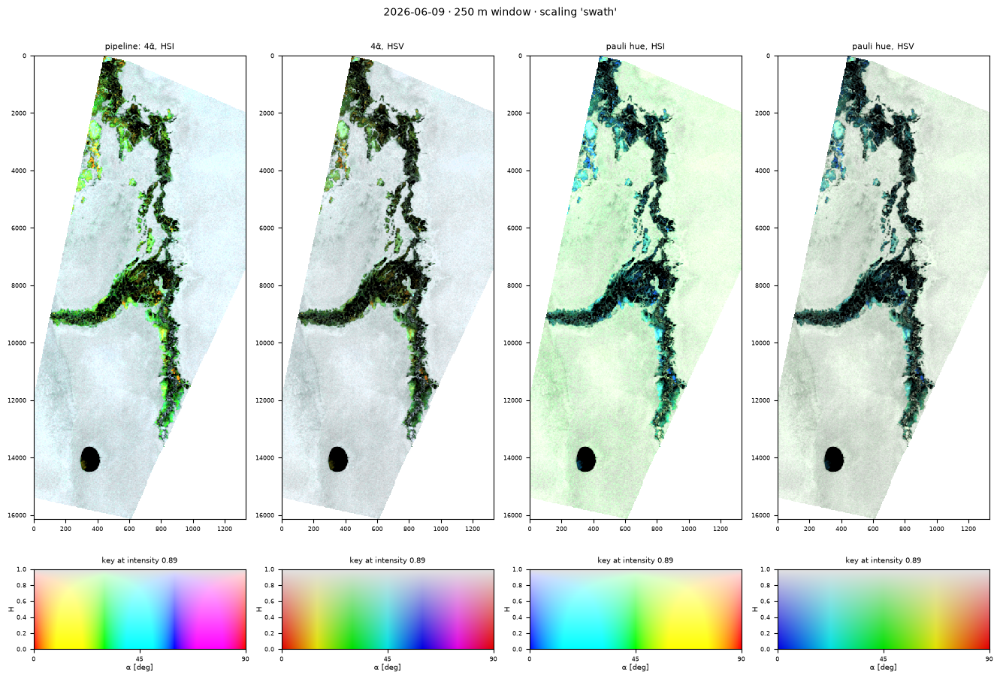

In [20]:
compare_hsi({
    "pipeline: 4ᾱ, HSI": dict(),
    "4ᾱ, HSV": dict(model="hsv"),
    "pauli hue, HSI": dict(hue_map="pauli"),
    "pauli hue, HSV": dict(hue_map="pauli", model="hsv"),
})

### 7b. Saturation (close-up)

At 250 m the forest has H ≈ 0.93 (section 6a), so 1 − H ≈ 0.07 and the forest is grey **by
construction**. There are two ways to show more colour:

* a **gamma < 1** on the saturation, (1 − H)^γ: it lifts all low saturations and keeps their order;
* **stretching H** between percentiles that bracket the forest values before 1 − H. The default
  `h_percentiles=(2, 98)` hardly changes anything, because its low end is set by the
  low-entropy water.

Both trade the absolute meaning of the saturation ("how pure") for visibility. Saturation 1
(hue only) shows the mechanism alone, which is the clearest view of where ᾱ changes.

pauli hue, HSV, 1−H                  intensity limits [-14.56  -3.21]   H limits [0 1]   clipped by the colour model: 0% of the cells
… (1−H)^0.4                          intensity limits [-14.56  -3.21]   H limits [0 1]   clipped by the colour model: 0% of the cells
… 1−H, H stretched 25–99.5 %         intensity limits [-14.56  -3.21]   H limits [0.91 0.98]   clipped by the colour model: 0% of the cells
… saturation 1 (hue only)            intensity limits [-14.56  -3.21]   H limits [0 1]   clipped by the colour model: 0% of the cells


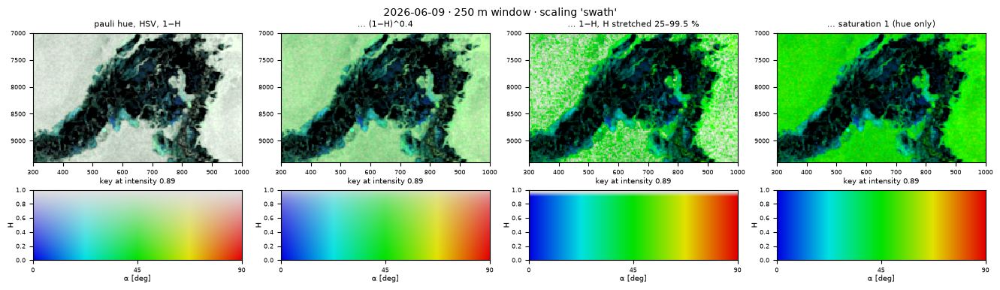

In [21]:
compare_hsi({
    "pauli hue, HSV, 1−H": dict(hue_map="pauli", model="hsv"),
    "… (1−H)^0.4": dict(hue_map="pauli", model="hsv", sat_gamma=0.4),
    "… 1−H, H stretched 25–99.5 %": dict(hue_map="pauli", model="hsv", sat="1-H_stretch", h_percentiles=(25, 99.5)),
    "… saturation 1 (hue only)": dict(hue_map="pauli", model="hsv", sat="one"),
}, view=ZOOM)

### 7c. Your turn

Same pattern as 5e. Try `hue_from="alpha_1"`, `i_max=0.5` with `model="hsi"`, the intensity
options (`intensity="span_db_fixed", limits=(-18, -1)` or `intensity="span_amp_q"`), or your
own hue function, e.g. `hue_map=lambda a: 300 * a / 90`.

hue from α1, pauli, HSV              intensity limits [-14.56  -3.21]   H limits [0 1]   clipped by the colour model: 0% of the cells
HSI with i_max 0.5                   intensity limits [-14.56  -3.21]   H limits [0 1]   clipped by the colour model: 0% of the cells
γ 0.5, span dB fixed (−18, −1)       intensity limits [-18  -1]   H limits [0 1]   clipped by the colour model: 0% of the cells
custom hue 300·α/90, γ 0.5           intensity limits [-14.56  -3.21]   H limits [0 1]   clipped by the colour model: 0% of the cells


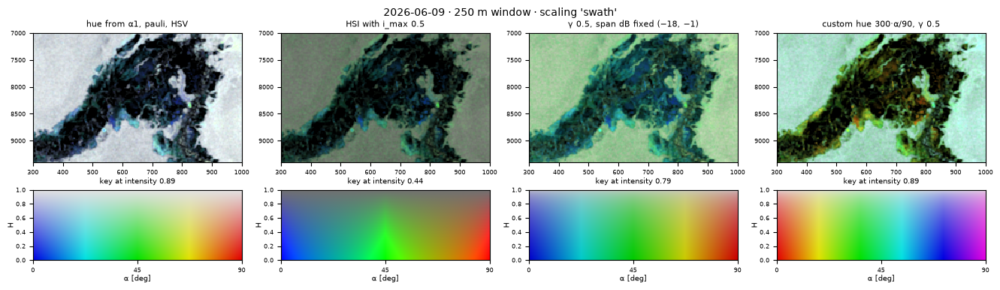

In [22]:
compare_hsi({
    "hue from α1, pauli, HSV": dict(hue_from="alpha_1", hue_map="pauli", model="hsv"),
    "HSI with i_max 0.5": dict(hue_map="pauli", i_max=0.5),
    "γ 0.5, span dB fixed (−18, −1)": dict(hue_map="pauli", model="hsv", sat_gamma=0.5,
                                           intensity="span_db_fixed", limits=(-18, -1)),
    "custom hue 300·α/90, γ 0.5": dict(hue_map=lambda a: 300 * a / 90, model="hsv", sat_gamma=0.5),
}, view=ZOOM)

## 8. Whole stack: per-scene vs stack-wide normalization

The point of a stack is comparing dates. If each scene is normalized with **its own**
statistics, a real change that affects the whole scene (more double bounce as the water rises,
a wetter canopy) is normalized away. **Stack-wide** statistics (one set of limits for all the
scenes, which is what the pipeline figures use) keep those changes visible. **Fixed** physical
limits keep them comparable across stacks too.

Set your recipe in `PAULI` and `HSI` (keyword arguments as in sections 5 and 7). The cell
recomputes all kept scenes with `WINDOW_M` and `SCALING`, which takes a few seconds per scene.

The line plot shows the mean Pauli powers per date. When all three channels move up and down
together, the cause is more likely a scene-wide radiometric offset than a change on the ground.
Per-scene normalization removes such an offset; stack-wide normalization keeps it. A real
flooding signal should show up as T22 moving *relative to* T11 and T33.

5 kept scenes, 250 m window, scaling 'swath'


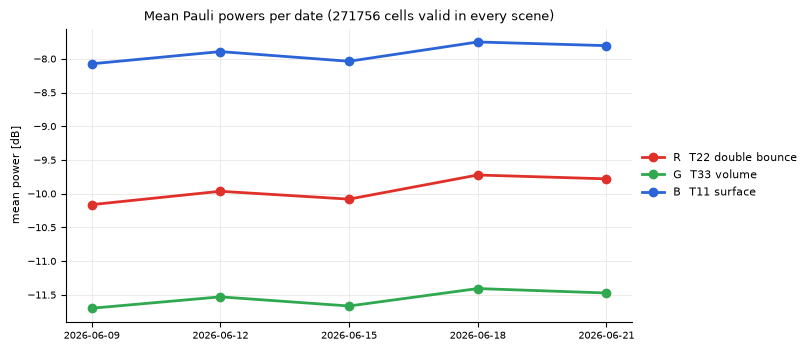

In [23]:
STACK = []
for k, p in enumerate(products):
    t3_full, finite = to_t3(SCALING, k)
    t3, good, geo = average_t3(t3_full, finite, WINDOW_M)
    STACK.append({"date": p["datetime"][:10], "t3": t3, "good": good, "geo": geo, "eig": eigen(t3)})
    del t3_full
print(f"{len(STACK)} kept scenes, {WINDOW_M:g} m window, scaling '{SCALING}'")

# mean Pauli powers per date on the cells valid in every scene: the real change across the stack
common = np.logical_and.reduce([s["good"] for s in STACK])
fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
for b, (name, color) in enumerate(PAULI_COLORS.items()):
    ax.plot([s["date"] for s in STACK], [db(np.mean(pauli_values(s["t3"], "power")[common][:, b])) for s in STACK],
            "-o", color=color, lw=2, ms=6, label=name)
ax.set_ylabel("mean power [dB]")
ax.set_title(f"Mean Pauli powers per date ({int(common.sum())} cells valid in every scene)", fontsize=9)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
ax.grid(color="#e4e3dd", lw=0.5)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

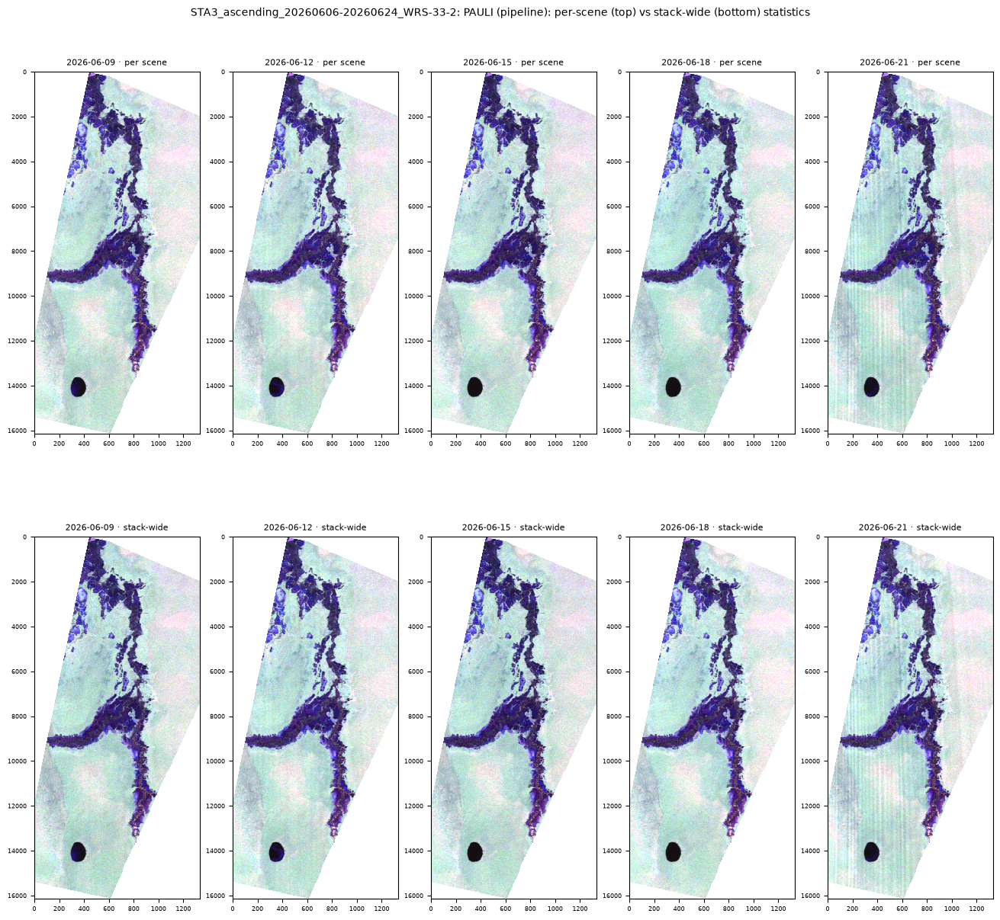

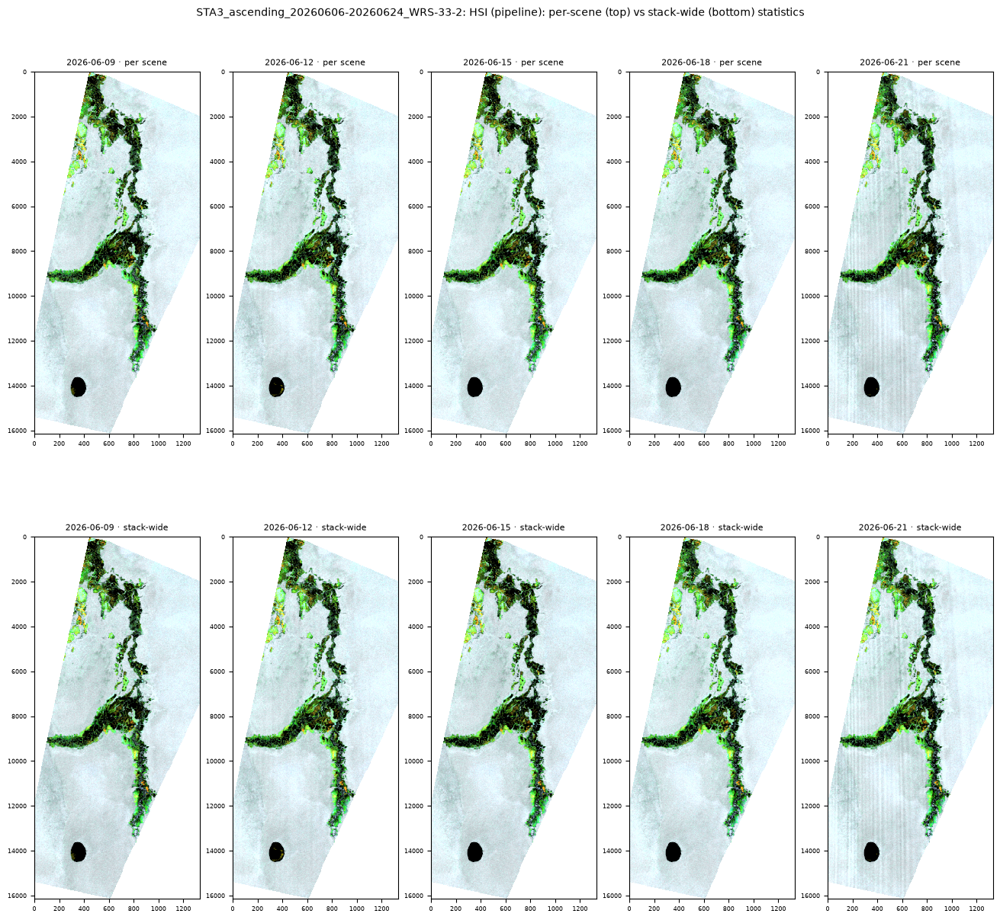

In [24]:
PAULI = dict()                                     # pipeline: amplitude, per channel 98 %
HSI = dict()                                       # pipeline: 4ᾱ, 1 − H, span dB 2–98 %, Gonzalez–Woods
# e.g. PAULI = dict(scale="db", clip="fixed", limits=FIXED_DB)
#      HSI = dict(hue_map="pauli", model="hsv", sat="1-H_stretch")


def plot_stack(kind, recipe, view=None, panel_w=2.6):
    """Rows: per-scene statistics, stack-wide statistics; columns: kept scenes in chronological order."""
    n = len(STACK)
    panel_h = float(np.clip(panel_w * view_ratio(view), 1.5, 8.0))
    fig, axes = plt.subplots(2, n, figsize=(panel_w * n, 2 * panel_h + 1), squeeze=False, layout="constrained")
    images = {}
    for row, scope in enumerate(("per scene", "stack-wide")):
        for col, s in enumerate(STACK):
            if kind == "pauli":
                stats = [(t["t3"], t["good"]) for t in STACK] if scope == "stack-wide" else None
                img = pauli_rgb_image(s["t3"], s["good"], stats=stats, **recipe)[0]
            else:
                stats = [(t["eig"], t["good"]) for t in STACK] if scope == "stack-wide" else None
                img = hsi_image(s["eig"], s["good"], stats=stats, **recipe)[0]
            images[scope, col] = img
            show(axes[row, col], img, s["geo"], f"{s['date']} · {scope}", view=view)
    fig.suptitle(f"{STACK_DIR.name}: {kind.upper()} {recipe or '(pipeline)'}: per-scene (top) vs stack-wide (bottom) statistics",
                 fontsize=10)
    plt.show()
    return images


PAULI_STACK = plot_stack("pauli", PAULI)
HSI_STACK = plot_stack("hsi", HSI)

### 8a. Check against the pipeline figures

With the default (pipeline) recipes, 250 m and `"swath"` scaling, the stack-wide rows must
equal the images of `<roi>/polsar/<stack>/figures/stack_pauli_hsi.png`. The pipeline's
private loader is used here only for this check.

In [25]:
if PAULI == {} and HSI == {} and WINDOW_M == 250 and SCALING == "swath" and npz_path.exists():
    from flooded_forest.plotting.polsar import _load_stack

    st = _load_stack(npz_path, STACK_DIR)
    if st["meta"]["dates"] == [s["date"] for s in STACK]:
        for kind, mine_imgs in (("pauli", PAULI_STACK), ("hsi", HSI_STACK)):
            diff = max(np.abs(mine_imgs["stack-wide", k] - st[kind][k])[..., :3][st["good"]].max() for k in range(len(STACK)))
            print(f"{kind}: max |notebook - pipeline| over all scenes = {diff:.1e}")
    else:
        print("the kept scenes differ from the pipeline result: rerun the pipeline PolSAR step first")
else:
    print("check skipped: it needs the pipeline recipes, a 250 m window and 'swath' scaling")

pauli: max |notebook - pipeline| over all scenes = 1.2e-07
hsi: max |notebook - pipeline| over all scenes = 3.0e-08


## Moving a recipe into the pipeline

| notebook | pipeline |
|---|---|
| `SCALING` | `processing/polsar.py::incidence_scale` (one θ per swath from `config.yaml`) |
| `WINDOW_M`, `average_t3` | `averaging_window` in `config.yaml`, `processing/averaging.py` |
| `pauli_rgb_image(scale, clip, q, …)` | `plotting/polsar.py::_stack_pauli` (√Tii, per-channel `PAULI_Q = 0.98`, stack-wide) |
| `hsi_image(hue_map, sat, intensity, model, …)` | `plotting/polsar.py::_stack_hsi` (hue 4ᾱ, 1 − H, `SPAN_PERCENTILES = (2, 98)`) and `plotting/common.py::hsi_to_rgb` |
| `draw_hsi_key` | `plotting/polsar.py::_draw_hsi_key` |